In [355]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

# *Imports*

In [356]:
import os
import re
import random
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
import wandb
seed = 42
random.seed(seed)
np.random.seed(seed)
sns.set_style('whitegrid')
print('Library loaded')


Library loaded


In [357]:
import os
import wandb
from kaggle_secrets import UserSecretsClient

# Kaggle Secret se key lo — automatically milegi
secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("✅ W&B login successful!")

wandb: WARNING Calling wandb.login() after wandb.init() has no effect.


✅ W&B login successful!


# *Load Data*

In [358]:
train_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
print(train_df.shape)
print(test_df.shape)

(2000, 8)
(500, 7)


In [359]:
train_df.head(5)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


# *Null Check*

In [360]:
print(train_df.info())
print(f"Null Values :\n{train_df.isnull().sum()}")
print(train_df['answer'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB
None
Null Values :
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64
answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64


# *Answer Distribution*

Text(0.5, 1.0, 'Answer Distribution')

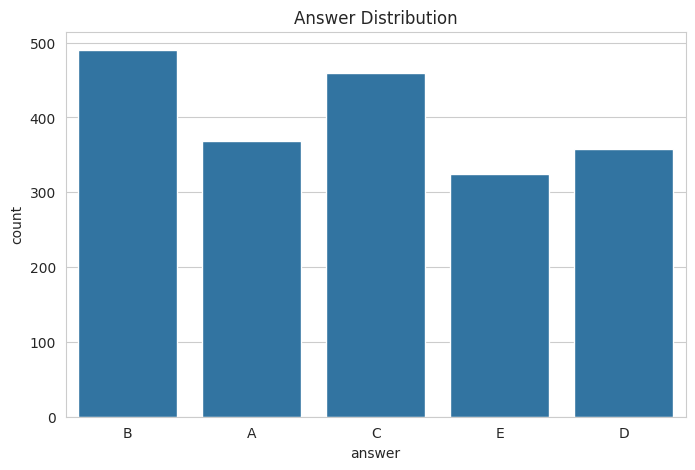

In [361]:
plt.figure(figsize=(8,5))
sns.countplot(x=train_df['answer'])
plt.title('Answer Distribution')

# *Text Cleaning*

In [362]:
# def clean_text(text):
#     text = str(text).lower()
#     text = re.sub(r'[^a-z0-9\s]','',text)
#     text = re.sub(r'\s+',' ',text)
#     return text.strip()

In [363]:
# train_df['prompt'] = train_df['prompt'].apply(clean_text)
# test_df['prompt'] = test_df['prompt'].apply(clean_text)
# for col in ['A','B','C','D','E']:
#     train_df[col] = train_df[col].apply(clean_text)
#     test_df[col] = test_df[col].apply(clean_text)
# print('Cleaning Text')

# *Convert Dataset for Classical ML*

In [364]:
# rows = []
# for _,row in train_df.iterrows():
#     for option in ['A','B','C','D','E']:
#         rows.append({
#              'text': row['prompt'] + '[SEP]' + row[option],
#              'label': 1 if option == row['answer'] else 0 ,
#              'question_id': row['id'],
#              'option': option
        
#         })
        
       
# ml_df = pd.DataFrame(rows)
# print('Expanded Shape:',ml_df.shape)
# ml_df.head(5)
        

In [365]:
# rows = []

# for _, row in train_df.iterrows():
#     for option in ['A','B','C','D','E']:
#         rows.append({
#             'text': clean_text(
#                 f"Question: {row['prompt']} Answer: {row[option]}"
#             ),
#             'label': 1 if option == row['answer'] else 0,
#             'question_id': row['id'],
#             'option': option
#         })

# ml_df = pd.DataFrame(rows)

# print(ml_df.head())

# *Train-Test Split*

In [366]:
# train_data , val_data = train_test_split(
#     ml_df , test_size = 0.2 , random_state = seed , stratify = ml_df['label']
# )
# print(train_data.shape)
# print(val_data.shape)

# *Tfidf*

In [367]:
# vectorizer = TfidfVectorizer(
#     max_features = 60000,
#     ngram_range = (1,2),
#     stop_words = 'english',
#     max_df = 0.95,
#     min_df = 2,
#     sublinear_tf = True
# )
# X_train = vectorizer.fit_transform(train_data['text'])
# X_val = vectorizer.transform(val_data['text'])
# y_train = train_data['label']
# y_val = val_data['label']
# print(X_train.shape)


# *Logistic Regression Model*

In [368]:
# lr_model = LogisticRegression(
#     C=4,
#     max_iter = 3000,
#     class_weight = 'balanced',
#     solver = 'liblinear',
#     random_state = seed
# )
# lr_model.fit(X_train,y_train)
# print('Logistic Regession Trained')

# *Validation Accuracy*

In [369]:
# from sklearn.metrics import classification_report
# val_preds = lr_model.predict(X_val)
# acc = accuracy_score(y_val,val_preds)
# print('Validation Accuracy:',acc)
# print(classification_report(y_val,val_preds))

# *MAP@3 Function*

In [370]:
def map_at_3(actual,predicted):
    scores = []
    for true_ans , pred_list in zip(actual,predicted):
        score = 0
        for rank,pred in enumerate(pred_list[:3],start=1):
            if pred ==true_ans:
                score = 1/rank
                break
        scores.append(score)
    return np.mean(scores)
print('Done')

Done


# *Logistic Regression Map@3*

In [371]:
# val_data['prob'] = lr_model.predict_proba(X_val)[:,1]

# grouped = val_data.groupby('question_id')

# predictions = []
# actuals = []

# for qid, group in grouped:
#     ranked = group.sort_values('prob', ascending=False)['option'].tolist()

#     predictions.append(ranked[:3])

#     actual = train_df.loc[train_df['id']==qid, 'answer'].values[0]
#     actuals.append(actual)

# score = map_at_3(actuals, predictions)

# print("Logistic Regression MAP@3:", score)

# *Naive Bayes*

In [372]:
# nb_model = MultinomialNB()

# nb_model.fit(X_train, y_train)

# val_data['nb_prob'] = nb_model.predict_proba(X_val)[:,1]

# predictions_nb = []

# for qid, group in val_data.groupby('question_id'):
#     ranked = group.sort_values('nb_prob', ascending=False)['option'].tolist()
#     predictions_nb.append(ranked[:3])

# score_nb = map_at_3(actuals, predictions_nb)

# print("Naive Bayes MAP@3:", score_nb)
# print(classification_report(y_val,val_preds))

# *Linear Svc*

In [373]:
# from sklearn.svm import LinearSVC
# from sklearn.metrics import classification_report
# model_Svc = LinearSVC(
#     C=4.0,
#     class_weight='balanced',
#     max_iter=6000
# )

# model_Svc.fit(X_train, y_train)

# val_pred = model_Svc.predict(X_val)

# print(classification_report(y_val, val_pred))


In [374]:
# # LinearSVC mein predict_proba nahi hota
# # decision_function use karo — higher score = zyada confident
# val_data['svc_prob'] = model_Svc.decision_function(X_val)

# predictions_svc = []
# actuals_svc = []

# for qid, group in val_data.groupby('question_id'):
#     ranked = group.sort_values('svc_prob', ascending=False)['option'].tolist()
#     predictions_svc.append(ranked[:3])

#     actual = train_df.loc[train_df['id'] == qid, 'answer'].values[0]
#     actuals_svc.append(actual)

# score_svc = map_at_3(actuals_svc, predictions_svc)
# print(f"LinearSVC MAP@3: {score_svc:.4f}")

# *LightGBM*

In [375]:
# from lightgbm import LGBMClassifier

# lgbm_model = LGBMClassifier(
#     n_estimators=500,
#     learning_rate=0.05,
#     num_leaves=31,
#     class_weight='balanced',
#     random_state=seed,
#     verbose=-1
# )
# lgbm_model.fit(X_train, y_train)

# val_data['lgbm_prob'] = lgbm_model.predict_proba(X_val)[:, 1]

# predictions_lgbm = []
# for qid, group in val_data.groupby('question_id'):
#     ranked = group.sort_values('lgbm_prob', ascending=False)['option'].tolist()
#     predictions_lgbm.append(ranked[:3])

# score_lgbm = map_at_3(actuals, predictions_lgbm)
# print(f"LightGBM MAP@3: {score_lgbm:.4f}")

# *Ensemble*

In [376]:
# val_data['ensemble_prob'] = (
#     val_data['prob'] * 0.4 +
#     val_data['lgbm_prob'] * 0.6
# )

# predictions_ensemble = []
# for qid, group in val_data.groupby('question_id'):
#     ranked = group.sort_values('ensemble_prob', ascending=False)['option'].tolist()
#     predictions_ensemble.append(ranked[:3])

# score_ensemble = map_at_3(actuals, predictions_ensemble)
# print(f"Ensemble MAP@3: {score_ensemble:.4f}")

# *Compare MOdels*

In [377]:
# results = pd.DataFrame({
#     'Model': ['Logistic Regression', 'LinearSVC','Naive Bayes','LightGBM','Ensemble'],
#     'MAP@3': [score, score_nb,score_svc,score_lgbm,score_ensemble]
# })

# results


# *Plot Results*

In [378]:
# plt.figure(figsize=(8,5))
# sns.barplot(data=results, x='Model', y='MAP@3')
# plt.axhline(0.85, linestyle='--')
# plt.title("Classical ML Comparison")
# plt.show()

In [379]:
# import os
# from kaggle_secrets import UserSecretsClient

# # API key Kaggle Secret se lo
# secrets = UserSecretsClient()
# os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
# wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)

# # W&B run start karo
# wandb.init(
#     project="23f2005181-t22026",
#     name="classical-ml",
#     config={
#         "vectorizer": "TF-IDF",
#         "train_size": len(train_data),
#         "val_size": len(val_data)
#     }
# )

# wandb.log({
#     "logistic_map3": score,
#     "linear_svc_mp@3":score_svc,
#     "naive_bayes_map3": score_nb,
#     "lgbm_map3": score_lgbm,
#     "ensemble_map3": score_ensemble
# })
# wandb.finish()
# print(" W&B done!")

In [380]:
# #sbmission for lrmodel
# test_rows = []
# for _, row in test_df.iterrows():
#     for option in ['A', 'B', 'C', 'D', 'E']:
#         test_rows.append({
#             'text': clean_text(f"Question: {row['prompt']} Answer: {row[option]}"),
           
#             'question_id': row['id'],
#             'option': option
#         })

# test_expanded = pd.DataFrame(test_rows)
# print('Test expanded shape:', test_expanded.shape)  # 2500 rows honi chahiye

# # Step 2 — Vectorize (fit nahi, sirf transform)
# X_test_vec = vectorizer.transform(test_expanded['text'])

# # Step 3 — Probability lo (class 1 = correct hone ki probability)
# test_expanded['prob'] = lr_model.predict_proba(X_test_vec)[:, 1]

# # Step 4 — Har question ke liye top 3 rank karo
# final_predictions = []
# for qid, group in test_expanded.groupby('question_id'):
#     ranked = group.sort_values('prob', ascending=False)['option'].tolist()
#     final_predictions.append(' '.join(ranked[:3]))

# # Step 5 — Submission banao
# submission = pd.DataFrame({
#     'ID': test_df['id'],
#     'Prediction': final_predictions
# })

# # Format check
# assert len(submission) == 500, '500 rows honi chahiye!'
# assert all(len(p.split()) == 3 for p in submission['Prediction']), 'Har row mein 3 options chahiye!'
# print('Format check passed!')
# print(submission.head(10))

# submission.to_csv('submission.csv', index=False)
# print('submission.csv ready!')

# Deep Learning Models

# *Pytorch Imports*

In [381]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForMultipleChoice
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import wandb
import os

In [382]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [383]:
class MCQVocabulary:
    def __init__(self, max_size=25000):
        self.max_size = max_size
        self.word2idx = {"<PAD>": 0, "<UNK>": 1}
        self.idx2word = {0: "<PAD>", 1: "<UNK>"}
        
    def build_vocab(self, text_list):
        word_counts = Counter()
        for text in text_list:
            word_counts.update(str(text).split())
            
        most_common = word_counts.most_common(self.max_size)
        for word, _ in most_common:
            if word not in self.word2idx:
                idx = len(self.word2idx)
                self.word2idx[word] = idx
                self.idx2word[idx] = word
                
    def numericalize(self, text):
        return [self.word2idx.get(word, self.word2idx["<UNK>"]) for word in str(text).split()]

# Pura raw text combine karke vocabulary build kar rahe hain
raw_texts = train_df['prompt'].astype(str).tolist()
for col in ['A', 'B', 'C', 'D', 'E']:
    raw_texts += train_df[col].astype(str).tolist()

vocab = MCQVocabulary()
vocab.build_vocab(raw_texts)
print(f"Vocabulary size built successfully: {len(vocab.word2idx)}")

Vocabulary size built successfully: 3957


In [384]:
class DeepMCQDataset(Dataset):
    def __init__(self, df, vocab, max_len=128, is_test=False):
        self.df = df.reset_index(drop=True)
        self.vocab = vocab
        self.max_len = max_len
        self.is_test = is_test
        self.label_map = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}
        
    def __len__(self):
        return len(self.df)
        
    def pad_and_truncate(self, tokens):
        if len(tokens) < self.max_len:
            return tokens + [self.vocab.word2idx["<PAD>"]] * (self.max_len - len(tokens))
        return tokens[:self.max_len]
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        prompt_tokens = self.vocab.numericalize(row['prompt'])
        
        input_sequences = []
        for option in ['A', 'B', 'C', 'D', 'E']:
            option_tokens = self.vocab.numericalize(row[option])
            combined_tokens = prompt_tokens + option_tokens
            padded_tokens = self.pad_and_truncate(combined_tokens)
            input_sequences.append(padded_tokens)
            
        X = torch.tensor(input_sequences, dtype=torch.long)
        
        if self.is_test:
            return X, torch.tensor(row['id'], dtype=torch.int)
            
        y = self.label_map[row['answer']]
        return X, torch.tensor(y, dtype=torch.long)
print('..')

..


In [385]:
class BiGRUMCQModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=256):
        super(BiGRUMCQModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.embed_dropout = nn.Dropout(0.2)

        
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True, bidirectional=True, num_layers=2)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )
        
    def forward(self, x):
        batch_size, num_options, max_len = x.shape
        x = x.view(-1, max_len)
        
        embedded = self.embedding(x)
        gru_out, _ = self.gru(embedded)
        
        pooled = torch.mean(gru_out, dim=1)
        scores = self.classifier(pooled)
        return scores.view(batch_size, num_options)
print("...")


...


In [386]:
dl_train_df, dl_val_df = train_test_split(train_df, test_size=0.2, random_state=seed)

train_dataset = DeepMCQDataset(dl_train_df, vocab, max_len=160)
val_dataset = DeepMCQDataset(dl_val_df, vocab, max_len=160)
test_dataset = DeepMCQDataset(test_df, vocab, max_len=160, is_test=True)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
print("done")

done


In [391]:
wandb.init(
    project="23f2005181-t22026",
    name="rnn-bigru-embed-droupout-160len",
    config={
        "architecture": "BiGRU",
        "embedding_dim": 128,
        "hidden_dim": 256,
        "epochs": 5,
        "batch_size": 32,
        "learning_rate": 8e-4
    }
)

In [392]:
model = BiGRUMCQModel(len(vocab.word2idx)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=8e-4, weight_decay=1e-4)

idx_to_letter = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E'}
epochs = 7

print("Starting deep learning sequence training...")
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * X_batch.size(0)
        
    epoch_train_loss = train_loss / len(train_loader.dataset)
    
    # Validation Step & MAP@3 Calculation
    model.eval()
    val_loss = 0.0
    actuals_list = []
    predictions_list = []
    
    with torch.no_grad():
        for X_val_batch, y_val_batch in val_loader:
            X_val_batch, y_val_batch = X_val_batch.to(device), y_val_batch.to(device)
            val_outputs = model(X_val_batch)
            
            loss = criterion(val_outputs, y_val_batch)
            val_loss += loss.item() * X_val_batch.size(0)
            
            # Predictions rank matching logic (Highest probability first)
            sorted_indices = torch.argsort(val_outputs, dim=1, descending=True).cpu().numpy()
            for idxs, true_lbl in zip(sorted_indices, y_val_batch.cpu().numpy()):
                predictions_list.append([idx_to_letter[i] for i in idxs[:3]])
                actuals_list.append(idx_to_letter[true_lbl])
                
    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_map3 = map_at_3(actuals_list, predictions_list)
    
    # Log metrics to W&B
    wandb.log({
        "epoch": epoch + 1,
        "train_loss": epoch_train_loss,
        "val_loss": epoch_val_loss,
        "val_map3": epoch_map3
    })
    
    print(f"Epoch {epoch+1}/{epochs} -> Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val MAP@3: {epoch_map3:.4f}")

wandb.finish()

Starting deep learning sequence training...
Epoch 1/7 -> Train Loss: 1.4536 | Val Loss: 1.1518 | Val MAP@3: 0.6796
Epoch 2/7 -> Train Loss: 0.9662 | Val Loss: 0.6573 | Val MAP@3: 0.8196
Epoch 3/7 -> Train Loss: 0.4923 | Val Loss: 0.4157 | Val MAP@3: 0.9508
Epoch 4/7 -> Train Loss: 0.6010 | Val Loss: 0.3373 | Val MAP@3: 0.9383
Epoch 5/7 -> Train Loss: 0.1982 | Val Loss: 0.1413 | Val MAP@3: 0.9767
Epoch 6/7 -> Train Loss: 0.0837 | Val Loss: 0.0706 | Val MAP@3: 0.9950
Epoch 7/7 -> Train Loss: 0.0435 | Val Loss: 0.0119 | Val MAP@3: 1.0000


epoch,▁▂▃▅▆▇█
train_loss,█▆▃▄▂▁▁
val_loss,█▅▃▃▂▁▁
val_map3,▁▄▇▇▇██
epoch,7
train_loss,0.04348
val_loss,0.01188
val_map3,1


In [394]:
model.eval()
test_ids = []
preds_string = []

print("Running test set inference...")
with torch.no_grad():
    for X_test_batch, id_batch in test_loader:
        X_test_batch = X_test_batch.to(device)
        test_outputs = model(X_test_batch)
        
        sorted_indices = torch.argsort(test_outputs, dim=1, descending=True).cpu().numpy()
        for idxs, qid in zip(sorted_indices, id_batch.numpy()):
            top3_letters = [idx_to_letter[i] for i in idxs[:3]]
            preds_string.append(" ".join(top3_letters))
            test_ids.append(qid)

# Create submission Dataframe structure matching exactly competition rule
submission_df = pd.DataFrame({
    'id': test_ids,
    'prediction': preds_string
})

# Format structural checks
assert len(submission_df) == 500, "Error: Submission file rows must be exactly 500"
print("Assert tests passed successfully!")

# Save to system environment
submission_df.to_csv('submission.csv', index=False)
print("submission.csv is perfect")

Running test set inference...
Assert tests passed successfully!
submission.csv is perfect
